# 04 — Exploratory Analysis of the Preprocessed Business Records

## 1. Purpose of This Notebook

This notebook describes the business dataset prepared in Notebook 02 before any feature is engineered. It uses
**only the Ministry of Commerce business records**; the economic indicators of GASTAT and SAMA are studied in
Sprint 3. Nothing is changed or saved, so the notebook can be run again at any time.

The notebook proceeds in six stages:

1. The labelled businesses and the time split.
2. Reliability of the survival target.
3. Distribution of the business characteristics.
4. Failure rate by business characteristic.
5. Missing values by outcome.
6. Failure rate by founding month.

**Test data never opened.** The time split of Notebook 05 is applied first. Only the training businesses (founded
from 2023 Q1 to 2024 Q4) are studied; the validation and test businesses are counted and then set aside, and their
outcome is not examined.

## 2. Environment Configuration

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    %pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.simplefilter('ignore', FutureWarning)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (11, 4)

businesses = pd.read_parquet(need(PIPE / '02_businesses.parquet', '02_preprocess_businesses'))
print(f'Businesses loaded from Notebook 02: {len(businesses):,}')

# English names, used in the charts because Arabic text is not shaped by the plotting library
SECTION_NAMES = {'A': 'Agriculture, forestry and fishing', 'B': 'Mining and quarrying', 'C': 'Manufacturing',
                 'D': 'Electricity and gas supply', 'E': 'Water supply and waste management', 'F': 'Construction',
                 'G': 'Wholesale and retail trade', 'H': 'Transportation and storage', 'I': 'Accommodation and food service',
                 'J': 'Information and communication', 'K': 'Financial and insurance', 'L': 'Real estate',
                 'M': 'Professional, scientific and technical', 'N': 'Administrative and support services',
                 'O': 'Public administration', 'P': 'Education', 'Q': 'Human health and social work',
                 'R': 'Arts, entertainment and recreation', 'S': 'Other service activities', 'T': 'Households as employers',
                 'U': 'Extraterritorial organizations', 'unclassified': 'unclassified'}
LEGAL_FORM_NAMES = {'مؤسسة فردية': 'Sole proprietorship', 'الشركة ذات المسؤولية المحدودة': 'Limited liability company',
                    'شركة التضامن': 'General partnership', 'فرع شركة أجنبية': 'Branch of a foreign company',
                    'شركة المساهمة': 'Joint stock company', 'شركة التوصية البسيطة': 'Limited partnership',
                    'شركة المساهمة المبسطة': 'Simplified joint stock company', 'غير محدد': 'Not specified'}
REGION_NAMES = {'الرياض': 'Riyadh', 'مكة المكرمة': 'Makkah', 'الشرقية': 'Eastern Province', 'القصيم': 'Qassim',
                'عسير': 'Asir', 'المدينة المنورة': 'Madinah', 'جازان': 'Jazan', 'نجران': 'Najran', 'حائل': 'Hail',
                'تبوك': 'Tabuk', 'الجوف': 'Al Jouf', 'الحدود الشمالية': 'Northern Borders', 'الباحة': 'Al Baha'}

Businesses loaded from Notebook 02: 2,115,778


## 3. Stage 1 — The Labelled Businesses and the Time Split

The labelled businesses are split by founding quarter, as in Notebook 05:

| Set | Founding quarters | Use |
|---|---|---|
| Training | 2023 Q1 to 2024 Q4 | Studied in this notebook |
| Validation | 2025 Q1 and 2025 Q2 | Comparison of models |
| Test | 2025 Q3 | Final evaluation, opened once |

            businesses  share
training        581351  65.6%
validation      183175  20.7%
test            121976  13.8%


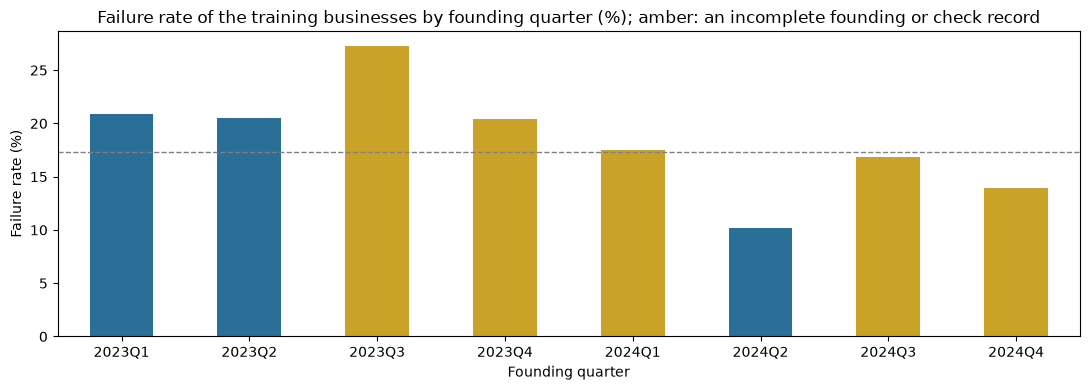

Training businesses: 581,351 | failed 100,691 (17.3%) | survived 480,660
                 businesses failed failure_rate  founding_record_complete  check_record_complete
founding_quarter                                                                                
2023Q1               49,921 10,404        20.8%                      True                   True
2023Q2               43,845  9,010        20.5%                      True                   True
2023Q3               54,054 14,746        27.3%                     False                  False
2023Q4               67,231 13,747        20.4%                      True                  False
2024Q1               74,421 13,038        17.5%                      True                  False
2024Q2               95,716  9,750        10.2%                      True                   True
2024Q3               92,821 15,606        16.8%                     False                  False
2024Q4              103,342 14,390        13.9%       

In [3]:
SPLIT = {'training': ('2023Q1', '2024Q4'), 'validation': ('2025Q1', '2025Q2'), 'test': ('2025Q3', '2025Q3')}
labelled = businesses[businesses['survived_first_year'].notna()]
split = pd.Series(pd.NA, index=labelled.index, dtype='string')
for name, (first, last) in SPLIT.items():
    split[labelled['founding_quarter'].between(first, last)] = name
assert split.notna().all(), 'A labelled business falls outside the split'
print(pd.DataFrame({'businesses': split.value_counts().reindex(SPLIT.keys()),
                    'share': split.value_counts(normalize=True).reindex(SPLIT.keys()).map('{:.1%}'.format)}).to_string())

training = labelled[split == 'training'].copy()
training['failed'] = 1 - training['survived_first_year'].astype(int)
del labelled, split

per_quarter = training.groupby('founding_quarter').agg(
    businesses=('failed', 'size'), failed=('failed', 'sum'), failure_rate=('failed', 'mean'),
    founding_record_complete=('founding_record_complete', 'first'), check_record_complete=('check_record_complete', 'first'))
colors = np.where(per_quarter['founding_record_complete'] & per_quarter['check_record_complete'], '#2a6f97', '#c9a227')
ax = (per_quarter['failure_rate'] * 100).plot.bar(color=colors, rot=0)
ax.axhline(training['failed'].mean() * 100, color='grey', ls='--', lw=1)
ax.set_title('Failure rate of the training businesses by founding quarter (%); amber: an incomplete founding or check record')
ax.set_xlabel('Founding quarter'); ax.set_ylabel('Failure rate (%)')
plt.tight_layout(); plt.show()
print(f'Training businesses: {len(training):,} | failed {int(training["failed"].sum()):,} ({training["failed"].mean():.1%}) | '
      f'survived {int((training["failed"] == 0).sum()):,}')
print(per_quarter.to_string(formatters={'businesses': '{:,}'.format, 'failed': '{:,}'.format, 'failure_rate': '{:.1%}'.format}))

**Result.** Of the 886,502 labelled businesses, 581,351 (65.6%) form the training set, 183,175 (20.7%) the validation set and
121,976 (13.8%) the test set. Of the training businesses, 100,691 failed (17.3%) and 480,660 survived. The failure
rate ranges from 10.2% (2024 Q2) to 27.3% (2023 Q3); only 2023 Q1, 2023 Q2 and 2024 Q2 have both a complete
founding record and a complete survival check record.

**Interpretation.** Failure is the minority outcome, about one business in six, so the model notebooks must treat the two classes as
imbalanced. The failure rate differs between founding quarters partly because of the completeness of the records;
the quarters with an incomplete record are kept and identified by their flags.

## 4. Stage 2 — Reliability of the Survival Target

Notebook 02 identifies groups of businesses whose label may be less reliable, without changing their label. This
cell gives the size and failure rate of each group among the training businesses:

| Group | Definition | Source |
|---|---|---|
| Failed, reappeared later | Absent at the survival check, present in a later record | Notebook 02, section 6.1 |
| First seen after the check | First recorded after the survival check quarter | Notebook 05 (feature extraction), section 3 |
| Founding record incomplete | Founded in an incomplete quarterly record | Notebook 02, section 6 |
| Check record incomplete | Checked in an incomplete quarterly record | Notebook 02, section 6 |
| Possible conversion | A company possibly converted from a sole proprietorship under a new number | Notebook 02, section 6.2 (scenario A) |
| Later legal-form transition | Sole proprietorship that later became a company with the same number | Notebook 02, section 6.2 (scenario B) |

In [4]:
training['first_seen_after_check'] = training['first_seen_quarter'] > training['survival_check_quarter']
groups = {'failed, reappeared later': training['label_reason'] == 'absent_at_check_reappeared_later',
          'first seen after the check': training['first_seen_after_check'],
          'founding record incomplete': ~training['founding_record_complete'],
          'check record incomplete': ~training['check_record_complete'],
          'possible conversion (scenario A)': training['possible_conversion'],
          'later legal-form transition (scenario B)': training['legal_form_transition_quarter'].notna()}
reliability = pd.DataFrame({'businesses': {g: int(m.sum()) for g, m in groups.items()},
                            'share of training': {g: m.mean() for g, m in groups.items()},
                            'failure rate': {g: training.loc[m, 'failed'].mean() for g, m in groups.items()}})
print(reliability.to_string(formatters={'businesses': '{:,}'.format, 'share of training': '{:.1%}'.format, 'failure rate': '{:.1%}'.format}))
print(f'\nFailure rate of all training businesses: {training["failed"].mean():.1%}')

                                         businesses share of training failure rate
failed, reappeared later                     26,362              4.5%       100.0%
first seen after the check                   20,769              3.6%       100.0%
founding record incomplete                  250,217             43.0%        17.9%
check record incomplete                     288,527             49.6%        19.8%
possible conversion (scenario A)                130              0.0%        23.1%
later legal-form transition (scenario B)      6,585              1.1%         8.6%

Failure rate of all training businesses: 17.3%


**Result.** 26,362 training businesses (4.5%) failed and reappeared in a later record. Among them, 20,769 (3.6% of the training
businesses) are first recorded after their survival check quarter. 43.0% of the training businesses were founded in
a quarter with an incomplete record (failure rate 17.9%), and 49.6% were checked in one (19.8%). 130 companies are
possible conversions under a new registration number (23.1% failed), and 6,585 sole proprietorships later become
companies under the same registration number (8.6% failed).

**Interpretation.** The 20,769 businesses first recorded after their survival check are the least reliable group: they are labelled
failed because they were absent at the check, but they exist in later records, and every characteristic they have
was recorded after the outcome. The conversion groups are too small to affect the labels noticeably (Notebook 02,
section 6.2.3). Incomplete records concern about half of the training businesses, so they cannot be excluded
without losing most quarters; they remain identified by their flags.

## 5. Stage 3 — Distribution of the Business Characteristics

The characteristics are those entered by a founder in Darb: legal form, region, sector, registered capital and
e-commerce. Registered capital is strongly skewed, so its distribution is shown on a logarithmic scale.


legal_form (share of training businesses)
legal_form
Sole proprietorship               70.6%
Limited liability company         29.0%
Branch of a foreign company        0.2%
Simplified joint stock company     0.1%
General partnership                0.1%
Joint stock company                0.0%
Limited partnership                0.0%
Not specified                      0.0%

region (share of training businesses)
region
Riyadh              38.1%
Makkah              19.0%
Eastern Province    15.4%
Qassim               4.9%
Madinah              4.9%
Asir                 4.7%
Jazan                3.2%
Najran               2.6%
Hail                 2.5%
Tabuk                2.2%
Al Jouf              1.0%
Northern Borders     0.9%
Al Baha              0.6%

sector (share of training businesses)
sector
unclassified                              28.3%
Construction                              27.7%
Wholesale and retail trade                12.4%
Accommodation and food service             7.9%
Tran


Registered capital (SAR), valid values:
count           581,018
mean            297,999
std          29,440,250
min                   1
10%               5,000
25%               5,000
50%               5,000
75%               5,000
90%              25,000
99%           1,000,000
max      20,263,227,750
Exactly 5,000 SAR: 76.0% | missing, zero or negative: 0.06%


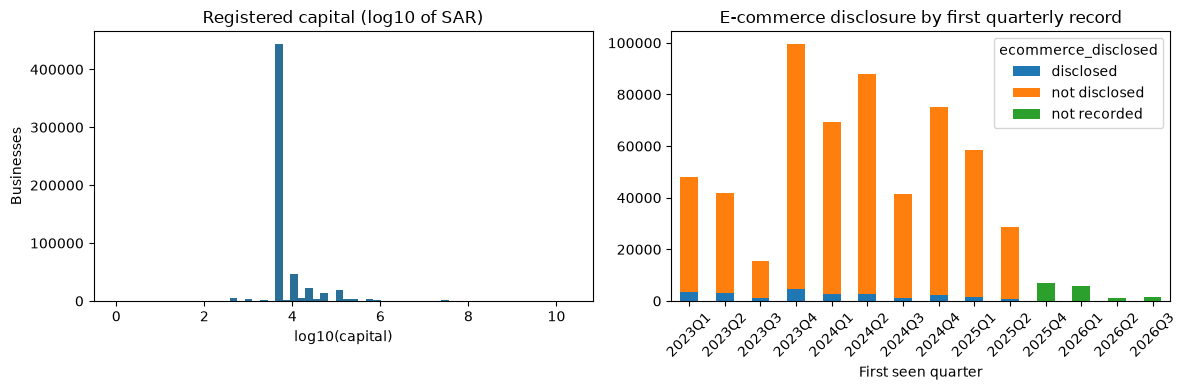

ecommerce_disclosed  disclosed  not disclosed  not recorded
first_seen_quarter                                         
2023Q1                    3373          44557             0
2023Q2                    3024          38969             0
2023Q3                    1014          14582             0
2023Q4                    4736          94753             0
2024Q1                    2535          66728             0
2024Q2                    2622          85168             0
2024Q3                    1319          40169             0
2024Q4                    2270          72875             0
2025Q1                    1729          56795             0
2025Q2                     580          28265             0
2025Q4                       0              0          6772
2026Q1                       0              0          5680
2026Q2                       0              0          1237
2026Q3                       0              0          1599


In [5]:
for column, names in [('legal_form', LEGAL_FORM_NAMES), ('region', REGION_NAMES), ('sector', SECTION_NAMES)]:
    shares = training[column].astype('string').map(lambda v: names.get(v, v)).value_counts(normalize=True, dropna=False)
    print(f'\n{column} (share of training businesses)')
    print(shares.map('{:.1%}'.format).to_string())

capital = training['registered_capital_sar'].where(training['registered_capital_flag'] == 'valid')
print('\nRegistered capital (SAR), valid values:')
print(capital.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).map('{:,.0f}'.format).to_string())
print(f'Exactly 5,000 SAR: {(capital == 5000).mean():.1%} | missing, zero or negative: {capital.isna().mean():.2%}')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.log10(capital.dropna()), bins=60, color='#2a6f97')
axes[0].set_title('Registered capital (log10 of SAR)'); axes[0].set_xlabel('log10(capital)'); axes[0].set_ylabel('Businesses')
ecommerce = training['ecommerce_disclosed'].map({1: 'disclosed', 0: 'not disclosed'}).astype('string').fillna('not recorded')
pd.crosstab(training['first_seen_quarter'], ecommerce).plot.bar(stacked=True, ax=axes[1], rot=45)
axes[1].set_title('E-commerce disclosure by first quarterly record'); axes[1].set_xlabel('First seen quarter')
plt.tight_layout(); plt.show()
print(pd.crosstab(training['first_seen_quarter'], ecommerce).to_string())

**Result.** Sole proprietorships make up 70.6% of the training businesses and limited liability companies 29.0%; the other
legal forms together hold less than 0.5%. Riyadh holds 38.1% of the businesses, Makkah 19.0% and the Eastern
Province 15.4%. The sector is `unclassified` for 28.3%; construction holds 27.7% and wholesale and retail trade
12.4%. Registered capital has a median of 5,000 SAR; 76.0% of the businesses register exactly 5,000 SAR, the 90th
percentile is 25,000 SAR and the maximum exceeds 20 billion SAR; it is missing, zero or negative for 0.06%.
E-commerce disclosure is recorded for every business first seen up to 2025 Q2, and for none of the 15,288
businesses first seen from 2025 Q4 onwards.

**Interpretation.** Registered capital is, for three businesses in four, the same amount, so it distinguishes few businesses and
describes the registration more than the founder's planned investment. Whether e-commerce is recorded depends only
on the quarter in which a business is first recorded, not on the business.

## 6. Stage 4 — Failure Rate by Business Characteristic

Each chart gives the failure rate of each category among the training businesses, with the number of businesses
in brackets; the dashed line is the failure rate of all training businesses. Categories with fewer than 200
businesses are not shown. Capital is divided into groups by its quintiles; because many businesses register
exactly the same capital, groups with the same boundaries are merged.

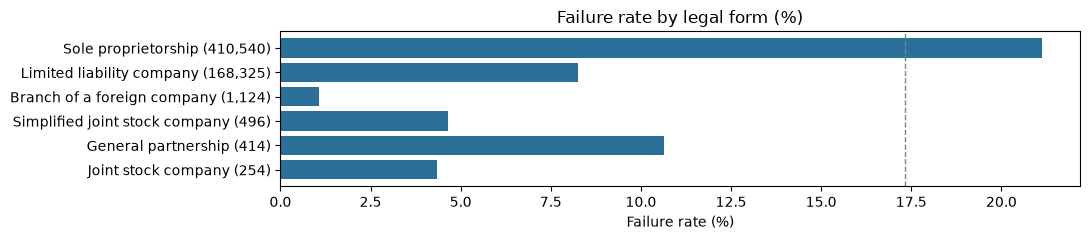

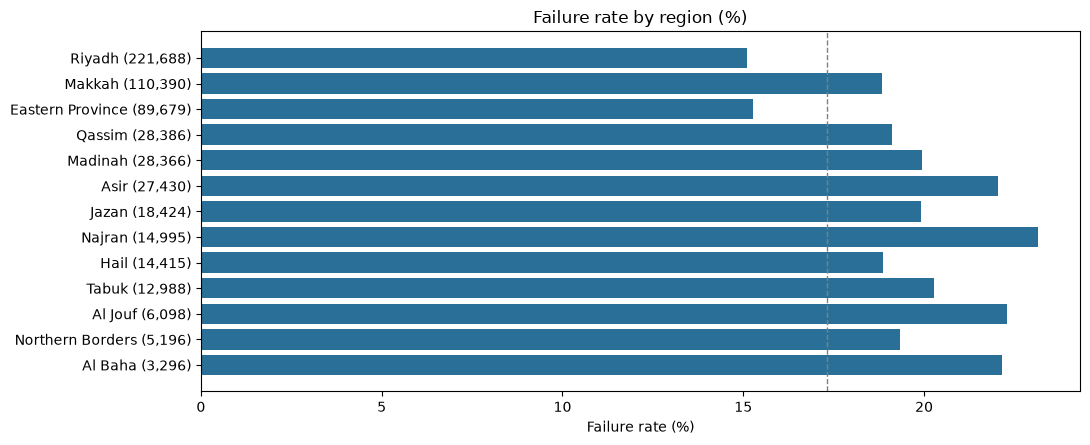

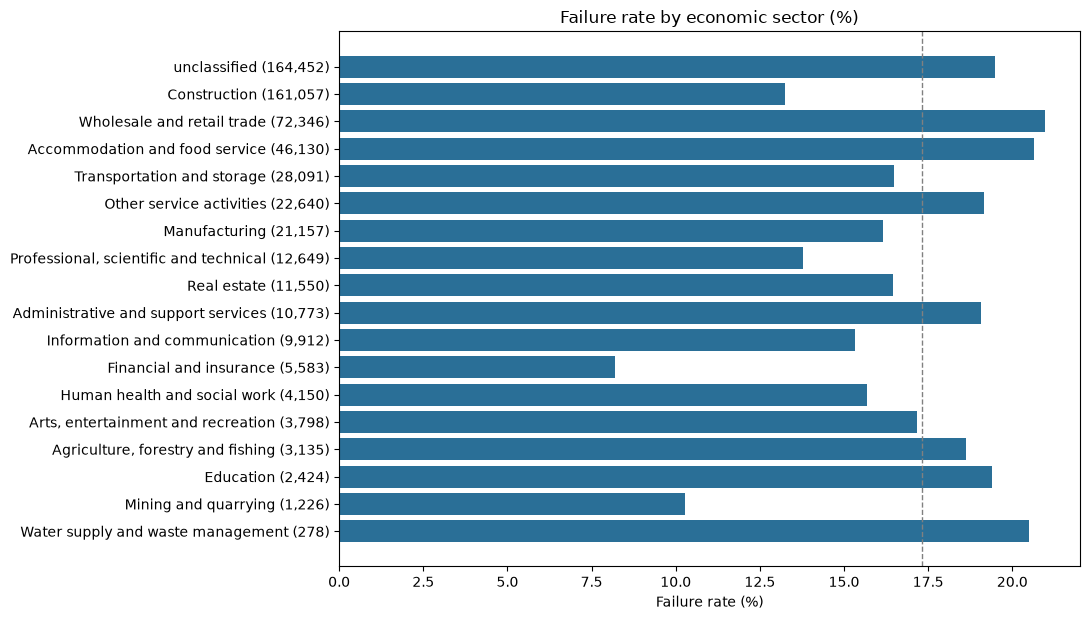

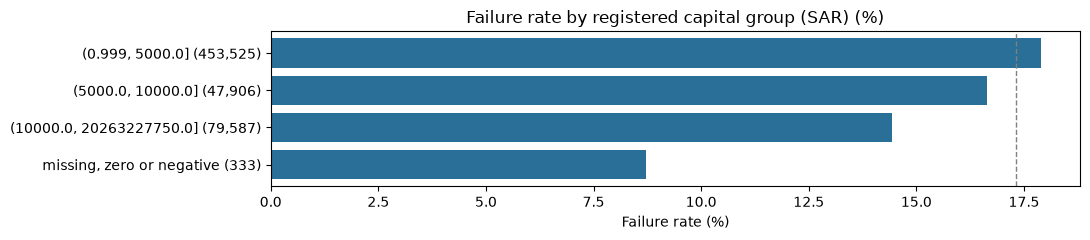

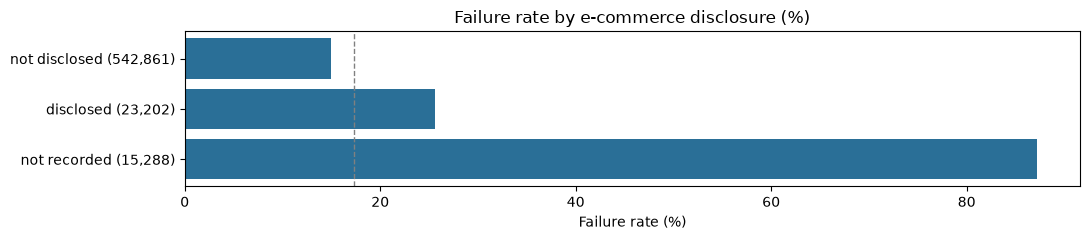

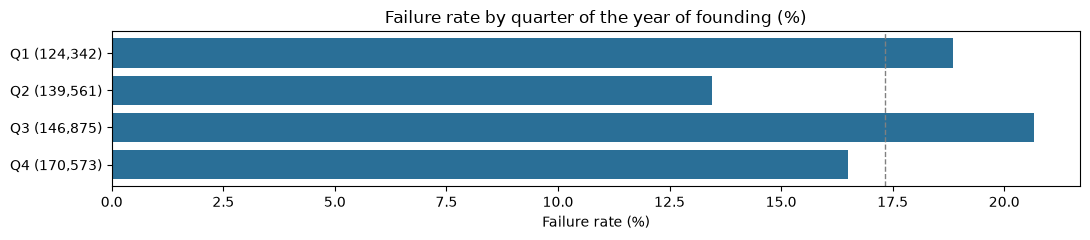


legal form
                               failure rate businesses
value                                                 
Sole proprietorship                   21.1%    410,540
Limited liability company              8.2%    168,325
Branch of a foreign company            1.1%      1,124
Simplified joint stock company         4.6%        496
General partnership                   10.6%        414
Joint stock company                    4.3%        254

region
                 failure rate businesses
value                                   
Riyadh                  15.1%    221,688
Makkah                  18.8%    110,390
Eastern Province        15.3%     89,679
Qassim                  19.1%     28,386
Madinah                 19.9%     28,366
Asir                    22.0%     27,430
Jazan                   19.9%     18,424
Najran                  23.2%     14,995
Hail                    18.9%     14,415
Tabuk                   20.3%     12,988
Al Jouf                 22.3%      6,098
Norther

In [6]:
OVERALL = training['failed'].mean()
def failure_chart(values, title, order=None, min_size=200):
    table = pd.DataFrame({'value': values, 'failed': training['failed']}).groupby('value', observed=True)['failed'].agg(['mean', 'size'])
    table = table[table['size'] >= min_size]
    table = table.reindex([o for o in order if o in table.index]) if order is not None else table.sort_values('size', ascending=False)
    labels = [f'{v} ({n:,})' for v, n in zip(table.index, table['size'])]
    fig, ax = plt.subplots(figsize=(11, max(2.5, 0.35 * len(table))))
    ax.barh(labels, table['mean'] * 100, color='#2a6f97')
    ax.axvline(OVERALL * 100, color='grey', ls='--', lw=1)
    ax.invert_yaxis(); ax.set_xlabel('Failure rate (%)'); ax.set_title(title)
    plt.tight_layout(); plt.show()
    return table.rename(columns={'mean': 'failure rate', 'size': 'businesses'})

tables = {}
tables['legal form'] = failure_chart(training['legal_form'].astype('string').map(LEGAL_FORM_NAMES), 'Failure rate by legal form (%)')
tables['region'] = failure_chart(training['region'].astype('string').map(REGION_NAMES), 'Failure rate by region (%)')
tables['sector'] = failure_chart(training['sector'].astype('string').map(SECTION_NAMES), 'Failure rate by economic sector (%)')
capital_group = pd.qcut(capital, 5, duplicates='drop')
tables['capital'] = failure_chart(capital_group.astype('string').fillna('missing, zero or negative'),
                                  'Failure rate by registered capital group (SAR) (%)',
                                  order=[str(c) for c in capital_group.cat.categories] + ['missing, zero or negative'])
tables['e-commerce'] = failure_chart(ecommerce, 'Failure rate by e-commerce disclosure (%)')
tables['quarter of the year'] = failure_chart('Q' + training['founding_quarter'].str[-1], 'Failure rate by quarter of the year of founding (%)',
                                              order=['Q1', 'Q2', 'Q3', 'Q4'])
for name, table in tables.items():
    print(f'\n{name}'); print(table.to_string(formatters={'failure rate': '{:.1%}'.format, 'businesses': '{:,}'.format}))

**Result.** Sole proprietorships fail at 21.1% and limited liability companies at 8.2%; the other legal forms fail at 1.1% to
10.6%. By region, the failure rate ranges from 15.1% (Riyadh) to 23.2% (Najran). By sector, it ranges from 8.2%
(financial and insurance) and 13.3% (construction) to 21.0% (wholesale and retail trade); unclassified businesses
fail at 19.5%. Registered capital forms only three groups: up to 5,000 SAR (17.9%), above 5,000 and up to 10,000
SAR (16.6%) and above 10,000 SAR (14.4%). Businesses that disclosed e-commerce fail at 25.6%, those that did not at
15.0%, and those without a recorded value at 87.2%. By quarter of the year, the failure rate ranges from 13.4% (Q2)
to 20.7% (Q3).

**Interpretation.** Legal form shows the largest and clearest difference among the business characteristics; region, sector and capital
show moderate differences. The e-commerce value `not recorded` is not a characteristic of the business but of the
time it was first recorded (Stage 3), and its failure rate reflects the businesses first recorded after their
survival check. The quarter of the year mixes seasonality with the differences between founding quarters: Q2
contains 2024 Q2 (10.2%) and Q3 contains 2023 Q3 (27.3%).

## 7. Stage 5 — Missing Values by Outcome

If a characteristic were missing much more often for one outcome, its absence would itself reveal the outcome.
The table gives, for each characteristic, the share of missing values among the surviving and the failed training
businesses; for the sector, `unclassified` is counted as missing. A difference above 5 points is flagged.

In [7]:
missing = pd.DataFrame({
    'region': training['region'].isna(), 'city': training['city'].isna(), 'legal_form': training['legal_form'].isna(),
    'registered capital': training['registered_capital_flag'] != 'valid', 'e-commerce': training['ecommerce_disclosed'].isna(),
    'sector': training['sector'] == 'unclassified', 'founding date': training['founding_date'].isna()})
by_outcome = pd.DataFrame({'missing (survived)': missing[training['failed'] == 0].mean(),
                           'missing (failed)': missing[training['failed'] == 1].mean()})
by_outcome['difference (points)'] = (by_outcome['missing (failed)'] - by_outcome['missing (survived)']) * 100
by_outcome['flag'] = np.where(by_outcome['difference (points)'].abs() > 5, 'difference above 5 points', '')
print(by_outcome.to_string(formatters={'missing (survived)': '{:.1%}'.format, 'missing (failed)': '{:.1%}'.format,
                                       'difference (points)': '{:+.1f}'.format}))

                   missing (survived) missing (failed) difference (points)                       flag
region                           0.0%             0.0%                +0.0                           
city                             0.0%             0.0%                +0.0                           
legal_form                       0.0%             0.0%                +0.0                           
registered capital               0.1%             0.0%                -0.0                           
e-commerce                       0.4%            13.2%               +12.8  difference above 5 points
sector                          27.5%            31.8%                +4.3                           
founding date                    0.0%             0.0%                +0.0                           


**Result.** Region, city, legal form and founding date are never missing, and registered capital is missing for 0.1% or less of
both outcomes. E-commerce is missing for 13.2% of the failed businesses against 0.4% of the surviving ones (+12.8
points), the only difference above 5 points. The sector is `unclassified` for 31.8% of the failed businesses
against 27.5% of the surviving ones (+4.3 points).

**Interpretation.** The absence of the e-commerce value reveals the outcome and must not enter the model in its present form. The
difference for the sector is moderate and comes from the business name, which is known at the founding (Notebook
05, feature extraction, section 4).

## 8. Stage 6 — Failure Rate by Founding Month

The number of businesses founded each month and their failure rate show whether the founding quarters differ in
composition, for example through the wave of limited liability companies of 2024 Q2 (Notebook 02, section 6.2.2).

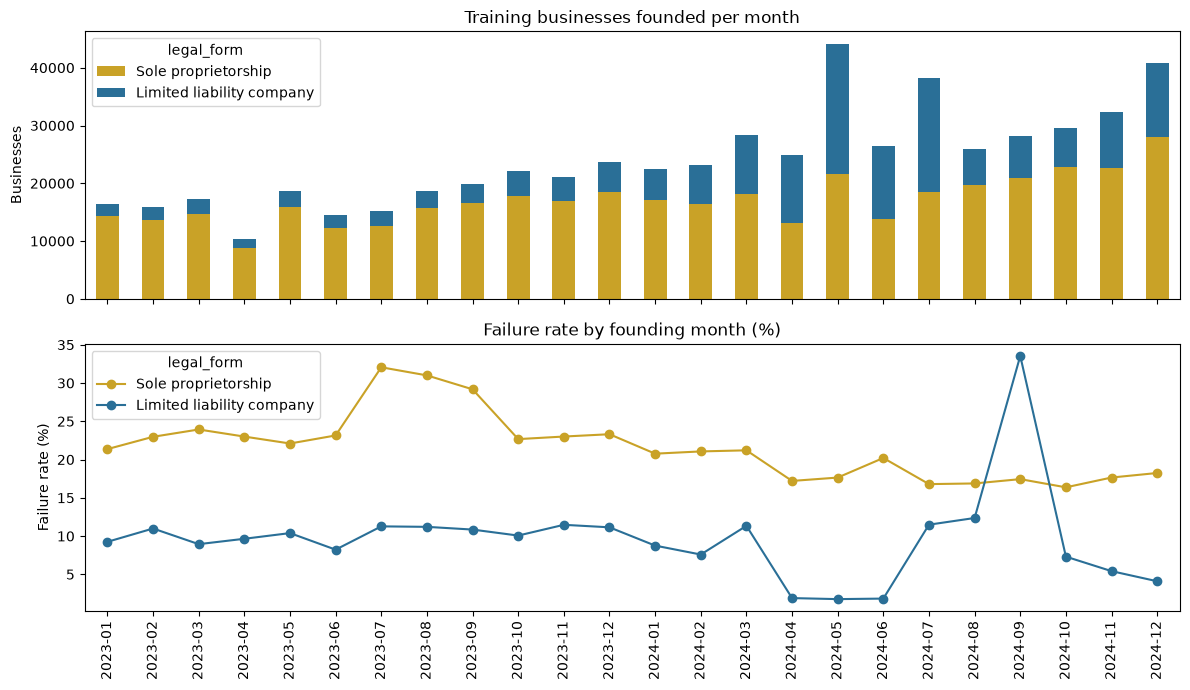

                       businesses                                  failure rate                          
legal_form    Sole proprietorship Limited liability company Sole proprietorship Limited liability company
founding_date                                                                                            
2023-01                    14,284                     2,216               0.214                     0.093
2023-02                    13,615                     2,284               0.230                     0.110
2023-03                    14,756                     2,549               0.239                     0.089
2023-04                     8,821                     1,617               0.230                     0.096
2023-05                    15,884                     2,820               0.221                     0.104
2023-06                    12,229                     2,225               0.231                     0.082
2023-07                    12,677             

In [8]:
month = training['founding_date'].dt.to_period('M').astype(str)
monthly = training.groupby([month, training['legal_form'].astype('string').map(LEGAL_FORM_NAMES)])['failed'].agg(['size', 'mean']).unstack()
main_forms = ['Sole proprietorship', 'Limited liability company']
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
monthly['size'][main_forms].plot.bar(stacked=True, ax=axes[0], color=['#c9a227', '#2a6f97'])
axes[0].set_title('Training businesses founded per month'); axes[0].set_ylabel('Businesses')
(monthly['mean'][main_forms] * 100).plot(ax=axes[1], marker='o', color=['#c9a227', '#2a6f97'], use_index=False)
axes[1].set_title('Failure rate by founding month (%)'); axes[1].set_ylabel('Failure rate (%)')
axes[1].set_xticks(range(len(monthly))); axes[1].set_xticklabels(monthly.index, rotation=90)
plt.tight_layout(); plt.show()
print(pd.concat({'businesses': monthly['size'][main_forms], 'failure rate': monthly['mean'][main_forms]}, axis=1)
      .to_string(float_format=lambda v: f'{v:.3f}' if v < 1 else f'{v:,.0f}'))

**Result.** Limited liability companies founded from April to June 2024 fail at 1.8% to 1.9%, against 7.6% to 12.4% for those
founded from January 2023 to August 2024 in the other months; those founded in September 2024 fail at 33.5%, and
those founded from October to December 2024 at 4.1% to 7.3%. The number of limited liability companies founded per
month reaches 22,474 in May 2024, against 1,617 to 19,810 in the other months. The failure rate of sole
proprietorships falls from 31.0% to 32.1% in July and August 2023 to between 16.4% and 21.2% in 2024.

**Interpretation.** The failure rate of limited liability companies changes sharply with the founding month: the companies founded from
April to June 2024, the wave of section 6.2.2 of Notebook 02, almost all survive, while those founded in September
2024 fail three times more often than usual. These companies are checked in the records of 2025 Q2 and 2025 Q3
respectively, the latter being incomplete. The records do not show whether these differences come from the
businesses or from the records used for the check; the founding quarter is therefore a likely source of differences
that a model may confuse with the effect of the legal form.

## 9. Limitations

1. Only the training businesses are studied; the relations may differ for the validation and test businesses.
2. Every relation shown is that of one characteristic alone; the characteristics are related to one another (Notebook 05, Stage 3).
3. The English names of the sectors, legal forms and regions in the charts are translations by the team; the official names are in Arabic.
4. The failure rate by founding month mixes the businesses themselves with the completeness of the records used for their survival check.

## 10. Summary of Findings

1. The training set holds 581,351 businesses founded from 2023 Q1 to 2024 Q4, with a failure rate of 17.3% (from 10.2% to 27.3% by founding quarter). The validation and test businesses were not examined.
2. 20,769 training businesses (3.6%) are first recorded after their survival check; they are labelled failed and all their characteristics are recorded after the outcome.
3. Legal form shows the largest difference in failure: 21.1% for sole proprietorships against 8.2% for limited liability companies.
4. Three businesses in four register exactly 5,000 SAR, so registered capital distinguishes few businesses.
5. The e-commerce value is missing for businesses first recorded from 2025 Q4; its absence reveals the outcome (13.2% of failed against 0.4% of surviving businesses) and must not enter the model in its present form.
6. Businesses without a sector fail somewhat more often (+4.3 points); the sector comes from the business name and is kept as its own category.
7. Limited liability companies founded from April to June 2024 almost all survive (failure 1.8% to 1.9%), while those founded in September 2024 fail at 33.5%; the cause is not established.